In [2]:
%pip install scipy matplotlib

   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
    --------------------------------------- 0.8/36.6 MB 3.7 MB/s eta 0:00:10
   - -------------------------------------- 1.6/36.6 MB 3.7 MB/s eta 0:00:10
   -- ------------------------------------- 2.4/36.6 MB 3.7 MB/s eta 0:00:10
   --- ------------------------------------ 3.1/36.6 MB 3.6 MB/s eta 0:00:10
   ---- ----------------------------------- 3.9/36.6 MB 3.6 MB/s eta 0:00:09
   ---- ----------------------------------- 4.5/36.6 MB 3.6 MB/s eta 0:00:09
   ----- ---------------------------------- 5.2/36.6 MB 3.6 MB/s eta 0:00:09
   ------ --------------------------------- 6.0/36.6 MB 3.6 MB/s eta 0:00:09
   ------- -------------------------------- 6.8/36.6 MB 3.6 MB/s eta 0:00:09
   -------- ------------------------------- 7.6/36.6 MB 3.6 MB/s eta 0:00:09
   -------- ------------------------------- 8.1/36.6 MB 3.6 MB/s eta 0:00:08
   ---------- ----------------------------- 9.2/36.6 MB 3.6 MB/s eta 0:00:08
   ---

In [3]:
import pandas as pd, numpy as np
from scipy import stats

expr = pd.read_csv("../person2/clean_expression.csv", index_col=0)
meta = pd.read_csv("../person2/clean_metadata.csv")

tum = meta[meta.condition=="Tumor"].set_index("patient_id").sample_id
nor = meta[meta.condition=="Normal"].set_index("patient_id").sample_id
pats = sorted(set(tum.index) & set(nor.index))            # 43 pairs
T = expr[tum.loc[pats].values].values
N = expr[nor.loc[pats].values].values

t, p = stats.ttest_rel(T, N, axis=1)                      # paired test per gene
res = pd.DataFrame({"gene": expr.index, "log2FC": (T-N).mean(1), "t_stat": t, "pvalue": p})

def bh(p):                                                # Benjamini–Hochberg
    p = np.asarray(p); n = len(p); o = np.argsort(p)
    r = np.minimum.accumulate((p[o]*n/np.arange(1, n+1))[::-1])[::-1]
    out = np.empty(n); out[o] = np.minimum(r, 1); return out

res["padj"] = bh(res.pvalue.fillna(1).values)
res = res.sort_values("padj")
sig = (res.padj < 0.05) & (res.log2FC.abs() >= 1)

In [4]:
print(len(pats), "pairs;", len(res), "genes")
print("FDR<0.05:", (res.padj < 0.05).sum(), "| with |log2FC|>=1:", sig.sum(),
      "| up:", (sig & (res.log2FC > 0)).sum(), "| down:", (sig & (res.log2FC < 0)).sum())

43 pairs; 13237 genes
FDR<0.05: 2706 | with |log2FC|>=1: 216 | up: 60 | down: 156


In [5]:
res.to_csv("de_results.csv", index=False)
res.head(15)

,gene,log2FC,t_stat,pvalue,padj
8390,G0S2,-1.507552,-12.992563,2.631584e-16,3.483427e-12
10937,RBP4,-3.540891,-12.365864,1.378033e-15,5.389974e-12
7296,AKAP12,-1.463029,-12.257951,1.841740e-15,5.389974e-12
10872,ITIH5,-1.580850,-12.273996,1.763834e-15,5.389974e-12
11471,PCDH9,-1.766810,-12.220779,2.035950e-15,5.389974e-12
2801,MAOA,-1.890160,-12.043292,3.293873e-15,6.239936e-12
7424,GYG2,-1.831594,-11.996557,3.741220e-15,6.239936e-12
2155,LPL,-1.761588,-11.993630,3.771209e-15,6.239936e-12
5175,ADIPOQ,-1.971309,-11.921716,4.590198e-15,6.751161e-12
6755,PDZD2,-1.534022,-11.870949,5.275430e-15,6.983086e-12


Matplotlib is building the font cache; this may take a moment.


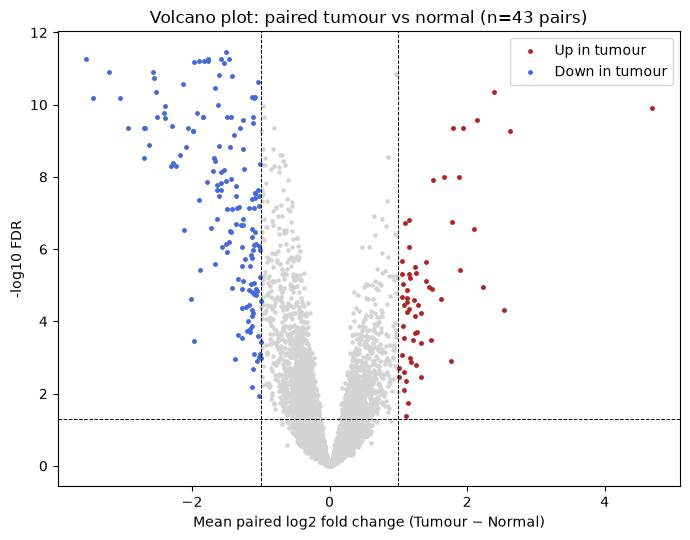

In [6]:
import matplotlib.pyplot as plt

res["nlp"] = -np.log10(res.padj.clip(lower=1e-300))
up = sig & (res.log2FC > 0)
dn = sig & (res.log2FC < 0)

plt.figure(figsize=(7, 5.5))
plt.scatter(res.log2FC, res.nlp, s=5, c="lightgrey")
plt.scatter(res.log2FC[up], res.nlp[up], s=6, c="firebrick", label="Up in tumour")
plt.scatter(res.log2FC[dn], res.nlp[dn], s=6, c="royalblue", label="Down in tumour")
for x in (-1, 1):
    plt.axvline(x, ls="--", c="k", lw=0.7)
plt.axhline(-np.log10(0.05), ls="--", c="k", lw=0.7)
plt.xlabel("Mean paired log2 fold change (Tumour − Normal)")
plt.ylabel("-log10 FDR")
plt.title("Volcano plot: paired tumour vs normal (n=43 pairs)")
plt.legend()
plt.tight_layout()
plt.savefig("volcano.png", dpi=200)
plt.show()

In [7]:
genes = ["BRCA1", "BRCA2", "RAD51", "PARP1", "TOP2A", "AURKA", "MKI67", "ERBB2"]
res[res.gene.isin(genes)][["gene", "log2FC", "pvalue", "padj"]]

,gene,log2FC,pvalue,padj
2574,AURKA,0.623682,0.000035,0.000700
6112,BRCA2,-0.311929,0.000687,0.007142
7416,ERBB2,0.472071,0.000820,0.008144
568,TOP2A,0.802741,0.000941,0.008980
6319,PARP1,0.251702,0.002778,0.019678
3307,RAD51,-0.137634,0.167952,0.322434
7659,MKI67,0.057543,0.355154,0.531466
2916,BRCA1,0.056870,0.713977,0.826417


## Stage 5: Differential gene expression

**Data:** 13,237 genes x 86 samples (log2-scale expression), 43 patients each with one tumour and one matched normal sample.

**Method:** Paired t-test per gene on log2 expression (tumour vs matched normal), with Benjamini-Hochberg FDR correction. Because the data are normalized log2 expression and not raw counts, this is an **exploratory** comparison, not count-based RNA-seq DE (DESeq2/edgeR). log2FC is the mean paired difference in log2 values.

**Threshold:** FDR < 0.05 and |log2FC| >= 1.

### Results
- 2,706 genes have FDR < 0.05; 216 also have |log2FC| >= 1 (60 higher in tumour, 156 lower).
- The strongest signals are mostly *lower* in tumour: G0S2, RBP4, ITIH5, MAOA, LPL, ADIPOQ, CIDEC. Many are adipose or lipid-metabolism genes, and AKR1C1/AKR1C2 are involved in steroid metabolism. This probably reflects normal breast tissue being fat-rich, so part of the signal is tissue composition and not only tumour biology.
- DNA-repair / proliferation genes: AURKA (+0.62), TOP2A (+0.80), ERBB2 (+0.47) and PARP1 (+0.25) are significant at FDR < 0.05 but below the |log2FC| >= 1 cutoff. BRCA2 is slightly lower (-0.31). BRCA1, RAD51 and MKI67 are not significant.

### What this does not show
These are associations, not causal effects. Results depend on how the data were normalized upstream, and a statistically significant gene with a small fold change may not be biologically large.